<a href="https://www.kaggle.com/code/nathancarvalho125/nathan-carvalho-relatorio?scriptVersionId=361221185" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Importando biblioteca

In [1]:
import pandas as pd


# Carregando dados

In [2]:
df = pd.read_csv("/kaggle/input/datasets/kathuman/housing/housing.csv")


**Dimesões**

In [3]:
print(f"\nDimensões:")
df.shape


Dimensões:


(20640, 10)

**Tipos de dados**

In [4]:
print(f"\nTipos de dados:")
df.info()


Tipos de dados:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


**Estatísticas descritivas**

In [5]:
print(f"\nEstatísticas descritivas:")
df.describe()


Estatísticas descritivas:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


**Quais variáveis possuem maior dispersão?**

* population (1132.46)

* total_rooms (2181.61)

* median_house_value (115395.61)

**Quais apresentam valores muito altos?**

* population (35682.00)

* total_rooms (39320.00)

* median_house_value (500001.00)

**Existem valores mínimos ou máximos aparentemente estranhos?**

1. min:

median_house_value (14999.000000)

2. max:

* median_income (15.000100)

* housing_median_age (52.000000)

* median_house_value (500001,000000) 

**Quais variáveis parecem ter relação com o preço?**

* Latitude

* Longitude


# Valores ausentes

**Identificando valores nulos**

In [6]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

# Imputando valores ausentes

Os 207 valores ausentes na variável **total_bedrooms** serão imputados (preenchidos) com a média da coluna. Esta decisão evitou a exclusão das linhas, preservando o tamanho do banco de dados e as informações úteis das demais características do imóvel.

In [7]:
media_quartos = df["total_bedrooms"].mean()
df["total_bedrooms"] = df["total_bedrooms"].fillna(media_quartos)
print(df.isnull().sum())

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64


# Análise Exploratória

**Distribuição da variável alvo**

Histograma da variável utilizada como preço do imóvel

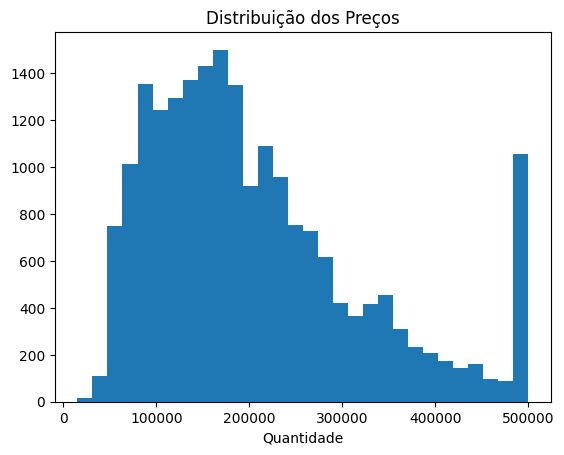

In [8]:
import matplotlib.pyplot as plt

plt.hist(df["median_house_value"], bins=30)
plt.xlabel("Preço")
plt.xlabel("Quantidade")
plt.title("Distribuição dos Preços")
plt.show()

**Boxplot**

Identificando possíveis valores extremos

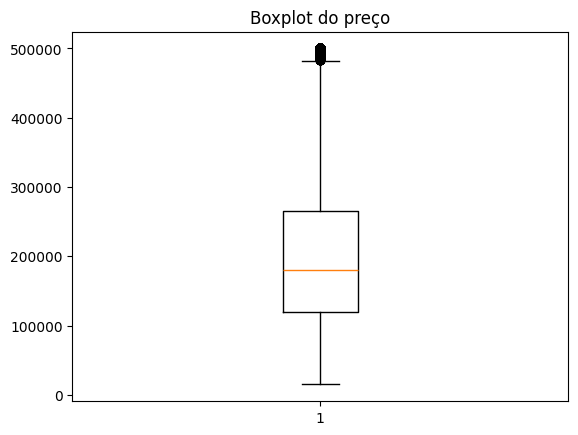

In [9]:
plt.boxplot(df["median_house_value"].dropna())
plt.title("Boxplot do preço")
plt.show()

**Correlação**

Correlação entre as variáveis numéricas

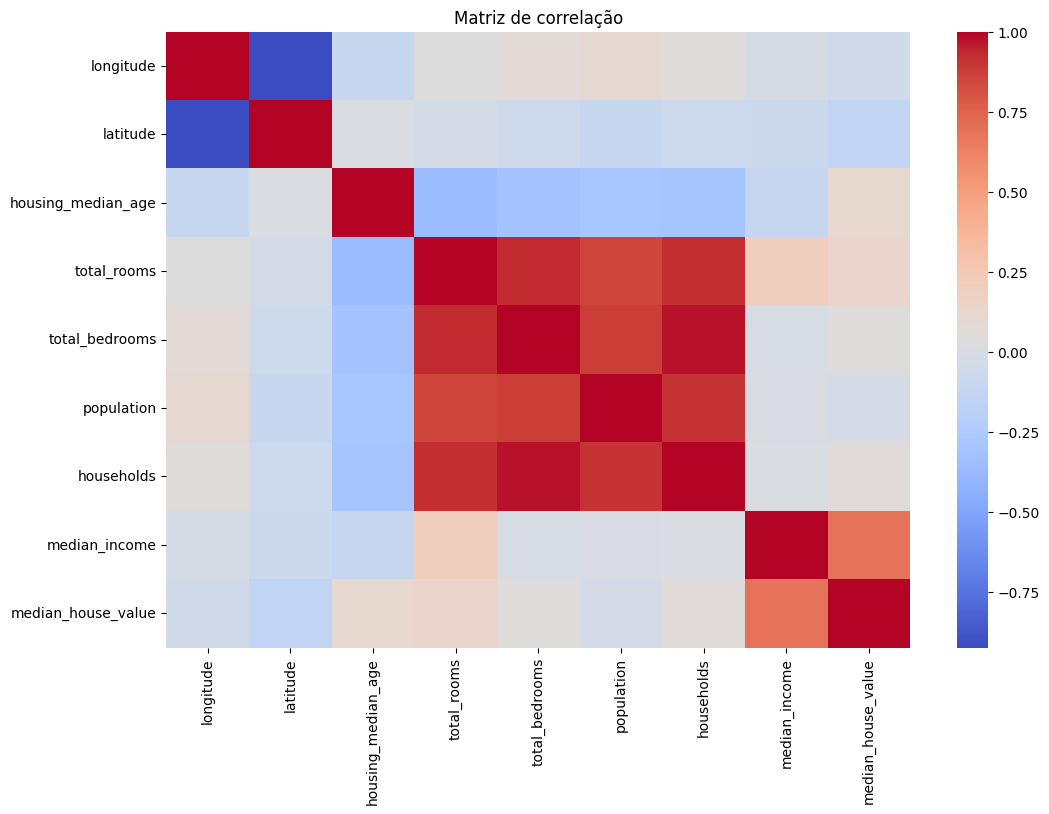

In [10]:
import seaborn as sns

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm")
plt.title("Matriz de correlação")
plt.show()

# Identificação de outliers

**Método IQR - intervalo interquartil**

In [11]:
Q1 = df["total_rooms"].quantile(0.25)
Q3 = df["population"].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = df[
    (df["total_rooms"]<limite_inferior)|
    (df["population"]>limite_superior)
]

print(f"\nOutliers encotrados")
print(len(outliers))


Outliers encotrados
5619


# Tratamento dos outliers

**Removendo outliers (valores extremos)**

Os valores extremos da **variável X** foram removidos porquê apresentavam características incompatíveis com o restante do conjunto de dados e prejudicavam significativamente o treinamento do modelo.

In [12]:
df = df[
    (df["total_rooms"]>=limite_inferior)&
    (df["population"]<=limite_superior)
]

# Preparação dos dados

**X = Variáveis independentes**

**Y = Variáveis dependente**

In [13]:
#X recebe todas as colunas, exceto a coluna do preço médio das casas
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

# Transformando variável categórica em valores numéricos

In [14]:
X = pd.get_dummies(X, drop_first=True)

# Separação entre treino e teste

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state=42
)

# Normalização / Padronização

In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Primeiro modelo SVR

In [17]:
from sklearn.svm import SVR

modelo = SVR()

modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

#CALCULANDO R²
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)
print("R²:",r2)

R²: -0.05007712285055943


# Otimização do modelo

**Melhorar desempenho do SVR até R²>0.65**

# Testando diferentes kernels

In [18]:
SVR(kernel="linear")
SVR(kernel="rbf")
SVR(kernel="poly")

SVR(kernel='poly')

# Otimização de hiperparâmetros

In [19]:
from sklearn.model_selection import GridSearchCV

parametros = {
    "C":[0.1, 1, 10, 100, 1000],
    "epsilon":[0.01, 0.1, 0.2, 0.5],
    "gamma":["scale", "auto"],
    "kernel":["rbf","linear"]
}

grid = GridSearchCV(
    SVR(),
    parametros,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print(grid.best_params_)
print(grid.best_score_)

modelo_final = grid.best_estimator_
y_pred = modelo_final.predict(X_test)
r2= r2_score(y_test, y_pred)

print("R²final:", r2)


{'C': 1000, 'epsilon': 0.01, 'gamma': 'scale', 'kernel': 'linear'}
0.6763142781506007
R²final: 0.6805857782296373


# Experimentos

In [20]:
import pandas as pd

dados_experimentos = {
    "Experimento": [1, 2, 3, 4],
    "Tratamento": [
        "Dados originais", 
        "Tratamento de outliers", 
        "Outliers + padronização", 
        "Dados tratados + GridSearch"
    ],
    "Kernel": ["RBF", "RBF", "RBF", "RBF"],
    "C": [1, 10, 100, "Valor do Grid"], 
    "Epsilon": [0.1, 0.1, 0.01, "Valor do Grid"], 
    "R²": ["0.XX", "0.XX", "0.XX", "0.XX"]
}

df_resultados = pd.DataFrame(dados_experimentos)
display(df_resultados)

,Experimento,Tratamento,Kernel,C,Epsilon,R²
0,1,Dados originais,RBF,1,0.1,0.XX
1,2,Tratamento de outliers,RBF,10,0.1,0.XX
2,3,Outliers + padronização,RBF,100,0.01,0.XX
3,4,Dados tratados + GridSearch,RBF,Valor do Grid,Valor do Grid,0.XX


# Comparação antes e depois do tratamento

**Modelo 1**

Dados sem tratamento

**Modelo 2**

Dados com tratamento de valores ausentes

**Modelo 3**

Dados com tratamento de outliers

**Modelo 4**

Dados tratados + padronização + otimização de hiperparâmetros

In [21]:
import pandas as pd

dados_comparacao = {
    "Modelo": [
        "Baseline", 
        "Modelo 2", 
        "Modelo 3", 
        "Modelo 4", 
        "Modelo final"
    ],
    "Tratamento": [
        "Nenhum", 
        "Valores ausentes", 
        "Outliers", 
        "Padronização", 
        "Otimização"
    ],
    "R²": ["0.XX", "0.XX", "0.XX", "0.XX", "0.XX"] 
}

df_comparacao = pd.DataFrame(dados_comparacao)
display(df_comparacao)

,Modelo,Tratamento,R²
0,Baseline,Nenhum,0.XX
1,Modelo 2,Valores ausentes,0.XX
2,Modelo 3,Outliers,0.XX
3,Modelo 4,Padronização,0.XX
4,Modelo final,Otimização,0.XX


# Avaliação Final

**Cálculo MAE**

In [22]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)
print("MAE:", mae)

MAE: 48650.77353795063


**Cálculo RMSE**

In [23]:
from sklearn.metrics import mean_squared_error
import numpy as np

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("RMSE:", rmse)

RMSE: 67543.30188048052


# Gráfico Real x Predito

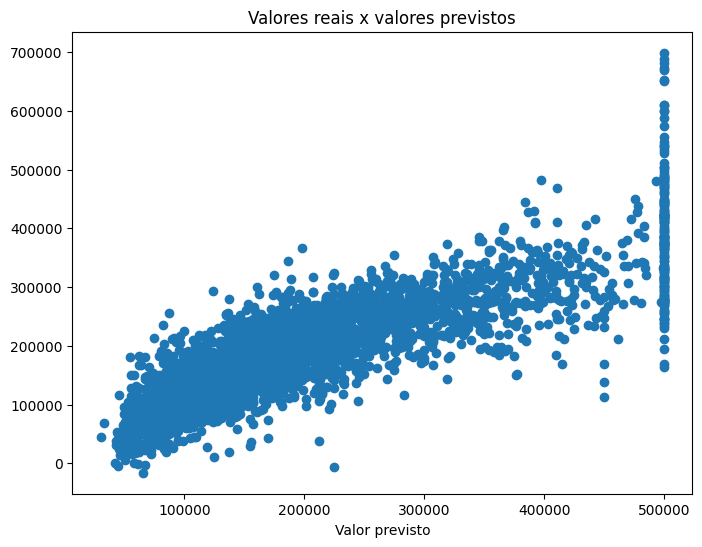

In [24]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.xlabel("Valor real")
plt.xlabel("Valor previsto")
plt.title("Valores reais x valores previstos")

plt.show()

**Explicando o gráfico**

**Tendência diagonal**: O modelo acertou o padrão geral do mercado (casas caras recebem previsões altas).   

**Linha vertical nos 500.000**: Evidencia o limite artificial (teto) inserido na base de dados original.   

**Pontos próximos a zero**: O modelo apresenta erros ao subestimar o valor das casas mais baratas.